<a href="https://colab.research.google.com/github/shanshiny06/Problem-Set-5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS5 — Right 93% of the Time
**Role:** Analyst, Credit Risk · **Name:** Yushan Li

## Phase 1: Build the Baseline Nobody Built
### Step 1.1 — The data

In [8]:
import numpy as np
import pandas as pd

SEED = 3916                          # Fixed seed so results are reproducible
rng = np.random.default_rng(SEED)
N = 10_000                           # Brief asks for >= 5,000; 10k gives ~200 defaults in the test set

# ---- Real features (will drive default in the next step) ----
income = rng.lognormal(mean=np.log(60_000), sigma=0.5, size=N)    # Lognormal: right-skewed, always positive
dti = np.clip(rng.beta(2, 5, size=N) * 0.8, 0.01, 0.8)           # Beta: naturally bounded between 0 and 1
credit_history_yrs = np.clip(rng.gamma(3, 3, size=N), 0.25, 40)  # Gamma: positive, right-skewed, mean ~9 years
prior_delinquencies = rng.poisson(lam=0.4, size=N)               # Poisson: non-negative counts, mostly 0
loan_amount = np.clip(income * rng.lognormal(np.log(0.3), 0.4, size=N),
                      1_000, 150_000)                            # ~30% of income, so correlated with income

# ---- Noise features (no true relationship to default, by construction) ----
months_at_address = rng.integers(1, 240, size=N)
num_bank_accounts = rng.integers(1, 8, size=N)
application_hour  = rng.integers(0, 24, size=N)
applicant_id_hash = rng.uniform(0, 1, size=N)   # Every value unique: high-cardinality noise, used in Phase 2

df = pd.DataFrame({
    "income": income, "dti": dti, "credit_history_yrs": credit_history_yrs,
    "prior_delinquencies": prior_delinquencies, "loan_amount": loan_amount,
    "months_at_address": months_at_address, "num_bank_accounts": num_bank_accounts,
    "application_hour": application_hour, "applicant_id_hash": applicant_id_hash,
})

df.describe().round(2)

,income,dti,credit_history_yrs,prior_delinquencies,loan_amount,months_at_address,num_bank_accounts,application_hour,applicant_id_hash
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,68625.80,0.23,9.06,0.41,22239.25,120.18,4.02,11.52,0.50
std,37656.53,0.13,5.19,0.64,15937.44,69.21,2.00,6.88,0.29
min,6066.61,0.01,0.25,0.00,1589.02,1.00,1.00,0.00,0.00
25%,43184.25,0.13,5.24,0.00,11714.78,60.00,2.00,6.00,0.25
50%,60022.91,0.21,8.09,0.00,18143.11,120.00,4.00,11.00,0.50
75%,84445.49,0.31,11.85,1.00,27860.67,180.00,6.00,18.00,0.75
max,441331.16,0.71,40.00,5.00,150000.00,239.00,7.00,23.00,1.00


In [9]:
from scipy.optimize import brentq
from scipy.special import expit       # expit(x) = 1 / (1 + e^-x), the logistic function

def z(s):
    # Standardise a feature so coefficients are on a comparable scale
    return (s - s.mean()) / s.std()

loan_to_income = df.loan_amount / df.income

# True data-generating process: only the real features appear here
linear_part = (
    -0.70 * z(np.log(df.income))                  # Higher income -> lower risk
    + 0.80 * z(df.dti)                            # Higher DTI -> higher risk
    + 0.60 * z(df.dti) ** 2                       # Non-linear: very high DTI is disproportionately risky
    - 0.50 * z(np.log(df.credit_history_yrs))     # Longer history -> lower risk
    + 0.55 * df.prior_delinquencies               # Each past delinquency adds risk
    + 0.40 * z(loan_to_income)                    # Loan size matters relative to income
)

# Solve for the intercept that makes the average default probability exactly 7%
TARGET = 0.07
b0 = brentq(lambda b: expit(b + linear_part).mean() - TARGET, -10, 5)

# Draw each applicant's outcome from their own default probability
df["default"] = rng.binomial(1, expit(b0 + linear_part))

TRUE_FEATURES  = ["income", "dti", "credit_history_yrs", "prior_delinquencies", "loan_amount"]
NOISE_FEATURES = ["months_at_address", "num_bank_accounts", "application_hour", "applicant_id_hash"]
FEATURES = TRUE_FEATURES + NOISE_FEATURES

print(f"Intercept b0 = {b0:.3f}")
print(f"Realised default rate: {df['default'].mean():.2%}")

Intercept b0 = -4.555
Realised default rate: 6.79%


**Finding (Step 1.1).** I simulated 10,000 loan applications, above the 5,000 minimum so that the test set contains enough defaults (~200) for stable precision-recall and significance estimates later. The realised default rate is 6.79%. The target was a 7% average default probability; the gap is sampling noise, since outcomes are Bernoulli draws and the standard error of the rate at n = 10,000 is about 0.26 percentage points.

Five features have a true relationship to default: income (protective), debt-to-income (risky, with a squared term so that very high DTI is disproportionately risky), credit history length (protective), prior delinquencies (risky), and loan amount, which enters through the loan-to-income ratio. Four features have no relationship by construction, because they never enter the data-generating process: months at address, number of bank accounts, application hour, and a uniform applicant ID hash. Because I know the true coefficients, I can later check which features each model correctly keeps or discards.

I split the data 70/30 into train and test before any exploration, stratified on default so both halves keep the same ~6.8% prevalence. Every number reported from here on comes from the 3,000-row test set.

### Step 1.2 — The null model

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

X = df[FEATURES]
y = df["default"]

# Split BEFORE any exploration; stratify keeps ~7% default in both halves
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

print(f"Train: {len(X_train):,} rows, {y_train.mean():.2%} default")
print(f"Test:  {len(X_test):,} rows, {y_test.mean():.2%} default ({y_test.sum()} defaults)")

# Null model: predict the majority class ("no default") for everyone
null = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_pred_null = null.predict(X_test)
acc_null = accuracy_score(y_test, y_pred_null)

# 95% confidence interval for the null accuracy (normal approximation)
se = np.sqrt(acc_null * (1 - acc_null) / len(y_test))

print(f"\nNull accuracy:  {acc_null:.4f}")
print(f"95% CI:         [{acc_null - 1.96*se:.4f}, {acc_null + 1.96*se:.4f}]")
print(f"Recall:         {recall_score(y_test, y_pred_null, zero_division=0):.2f}")
print("Confusion matrix [[TN FP] [FN TP]]:")
print(confusion_matrix(y_test, y_pred_null))

Train: 7,000 rows, 6.79% default
Test:  3,000 rows, 6.80% default (204 defaults)

Null accuracy:  0.9320
95% CI:         [0.9230, 0.9410]
Recall:         0.00
Confusion matrix [[TN FP] [FN TP]]:
[[2796    0]
 [ 204    0]]


**Finding (Step 1.2).** The null model predicts "no default" for every applicant. On the test set it scores 93.2% accuracy (95% CI: 92.3%–94.1%) with a recall of zero: all 204 defaulters are approved, and every one of those loans is lost. Its accuracy comes entirely from the 2,796 applicants who were never going to default.

This is the floor. The vendor's 93% sits inside the null model's confidence interval, so on its own it is indistinguishable from a model that has learned nothing. The sentence for the meeting: **"A model that approves everyone is right 93% of the time on our data, so the vendor's 93% tells us nothing until they show us how many defaults it actually catches."**

## Phase 2: Fit and Regularise
### Step 2.1 — Logistic regression, then penalised

In [11]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # Silence sklearn API-transition notices

import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# sklearn >= 1.8 sets the penalty via l1_ratio; older versions use penalty=...
NEW_API = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)

def make_logit(kind, C=1.0):
    """kind = 'none' (plain logit), 'lasso' (L1) or 'ridge' (L2). Smaller C = stronger penalty."""
    if kind == "none":
        clf = (LogisticRegression(C=np.inf, max_iter=10000) if NEW_API
               else LogisticRegression(penalty=None, max_iter=10000))
    else:
        r = 1.0 if kind == "lasso" else 0.0
        clf = (LogisticRegression(C=C, l1_ratio=r, solver="saga", max_iter=10000) if NEW_API
               else LogisticRegression(C=C, penalty="l1" if kind == "lasso" else "l2",
                                       solver="saga", max_iter=10000))
    # Standardise first: the penalty treats all coefficients alike, so features must share a scale
    return make_pipeline(StandardScaler(), clf)

# Plain (unpenalised) logistic regression
logit = make_logit("none").fit(X_train, y_train)

# Cross-validate LASSO and Ridge over a grid of penalty strengths, on the TRAINING set only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
Cs = np.logspace(-3, 2, 26)              # From very strong (0.001) to very weak (100) penalty

cv_results = {}
for kind in ["lasso", "ridge"]:
    rows = []
    for C in Cs:
        # Log loss, not accuracy: at 7% prevalence accuracy barely moves across models
        scores = -cross_val_score(make_logit(kind, C), X_train, y_train,
                                  cv=cv, scoring="neg_log_loss")
        rows.append((C, scores.mean(), scores.std() / np.sqrt(len(scores))))
    cv_results[kind] = pd.DataFrame(rows, columns=["C", "cv_logloss", "se"])

print(f"sklearn {sklearn.__version__}, new API: {NEW_API}")
cv_results["lasso"].round(4)

sklearn 1.6.1, new API: False


,C,cv_logloss,se
0,0.0010,0.2481,0.0000
1,0.0016,0.2481,0.0000
2,0.0025,0.2108,0.0006
3,0.0040,0.1894,0.0019
4,0.0063,0.1800,0.0027
5,0.0100,0.1742,0.0033
6,0.0158,0.1666,0.0035
7,0.0251,0.1626,0.0037
8,0.0398,0.1606,0.0039
9,0.0631,0.1587,0.0043


In [12]:
def pick_C(table):
    """Return (C at minimum CV log loss, largest-penalty C within 1 SE of that minimum)."""
    best = table["cv_logloss"].idxmin()
    threshold = table.loc[best, "cv_logloss"] + table.loc[best, "se"]
    C_min = table.loc[best, "C"]
    C_1se = table.loc[table["cv_logloss"] <= threshold, "C"].min()   # Smallest C = strongest penalty
    return C_min, C_1se

lasso_Cmin, lasso_C1se = pick_C(cv_results["lasso"])
ridge_Cmin, _          = pick_C(cv_results["ridge"])
print(f"LASSO: C_min = {lasso_Cmin:.4f}, C_1se = {lasso_C1se:.4f}")
print(f"Ridge: C_min = {ridge_Cmin:.4f}")

# Refit on the full training set at the selected penalties
lasso_min = make_logit("lasso", lasso_Cmin).fit(X_train, y_train)
lasso_1se = make_logit("lasso", lasso_C1se).fit(X_train, y_train)
ridge     = make_logit("ridge", ridge_Cmin).fit(X_train, y_train)

# Compare standardised coefficients against the truth we built
coefs = pd.DataFrame({
    "truly_relevant": [f in TRUE_FEATURES for f in FEATURES],
    "logit":     logit[-1].coef_[0],
    "lasso_min": lasso_min[-1].coef_[0],
    "lasso_1se": lasso_1se[-1].coef_[0],
    "ridge":     ridge[-1].coef_[0],
}, index=FEATURES).round(3)
print(coefs)

# Which features did each LASSO drive to EXACTLY zero?
for name, col in [("LASSO (C_min)", "lasso_min"), ("LASSO (1-SE)", "lasso_1se")]:
    zeroed = coefs.index[coefs[col] == 0].tolist()
    noise_found = [f for f in zeroed if f in NOISE_FEATURES]
    real_lost   = [f for f in zeroed if f in TRUE_FEATURES]
    print(f"\n{name} zeroed: {zeroed}")
    print(f"  Noise features correctly dropped: {len(noise_found)} of {len(NOISE_FEATURES)}")
    print(f"  Real features wrongly dropped:    {len(real_lost)} {real_lost}")

LASSO: C_min = 0.3981, C_1se = 0.0251
Ridge: C_min = 0.3981
                     truly_relevant  logit  lasso_min  lasso_1se  ridge
income                         True -1.133     -1.072     -0.421 -1.077
dti                            True  1.824      1.800      1.559  1.794
credit_history_yrs             True -0.489     -0.473     -0.296 -0.478
prior_delinquencies            True  0.373      0.362      0.227  0.365
loan_amount                    True  0.550      0.505      0.000  0.513
months_at_address             False  0.028      0.020      0.000  0.028
num_bank_accounts             False  0.051      0.041      0.000  0.049
application_hour              False -0.044     -0.036      0.000 -0.044
applicant_id_hash             False -0.133     -0.124     -0.013 -0.131

LASSO (C_min) zeroed: []
  Noise features correctly dropped: 0 of 4
  Real features wrongly dropped:    0 []

LASSO (1-SE) zeroed: ['loan_amount', 'months_at_address', 'num_bank_accounts', 'application_hour']
  Noise fe

**Finding (Step 2.1).** I fitted plain logistic regression, then LASSO (L1) and Ridge (L2) on standardised features, choosing the penalty by 5-fold cross-validated log loss on the training set. Log loss rather than accuracy, because Phase 1 showed accuracy barely discriminates between models at 7% prevalence. At the strongest penalty, every coefficient is zero and CV log loss is 0.248, which is exactly the entropy of a 6.79% base rate: the probabilistic version of the null model.

The CV curve is almost flat for C between 0.25 and 100, so the minimum-loss penalty (C = 0.398) is nearly unpenalised. That LASSO zeroes nothing, and its coefficients barely differ from plain logit or Ridge. With 7,000 rows and only 9 features there is little overfitting for regularisation to fix. Using the one-standard-error rule (the strongest penalty whose CV loss is within 1 SE of the minimum, C = 0.025), LASSO zeroes four features: three of the four true noise features (months at address, number of bank accounts, application hour) and one real feature, loan amount. The fourth noise feature, the applicant ID hash, survives with a negligible coefficient (−0.013) from a chance correlation in the training sample.

Loan amount was discarded because it was built as a multiple of income, so the two are highly correlated, and its true effect runs through the loan-to-income ratio, which the model never sees. LASSO tends to keep one of a correlated pair and drop the other; income's coefficient shrinks from −1.07 to −0.42 as it absorbs part of loan amount's role.

**Why Ridge shrinks but does not zero.** The L1 penalty |β| has a constant slope at zero, so whenever a feature's marginal contribution to the fit is smaller than the penalty, the optimum sits exactly at β = 0. The L2 penalty β² is flat at zero, so moving a coefficient slightly away from zero costs almost nothing and always helps the fit a little; coefficients shrink toward zero but never reach it. I would prefer LASSO when I suspect many features are irrelevant and want a sparse, explainable model, which matters to a lender who must justify each input to a regulator. I would prefer Ridge when features are correlated and all plausibly relevant: LASSO's choice among correlated features is unstable, as dropping loan amount shows, while Ridge spreads weight across them.

### Step 2.2 — A model that is not linear

In [13]:
from sklearn.ensemble import RandomForestClassifier

# 500 trees, each fitted on a bootstrap resample; oob_score scores every training row
# using only the trees that never saw it -> a free held-out estimate
rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True,
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)

acc_rf_test = accuracy_score(y_test, rf.predict(X_test))
print(f"OOB accuracy (training rows, unseen trees only): {rf.oob_score_:.4f}")
print(f"Test accuracy:                                    {acc_rf_test:.4f}")
print(f"Gap:                                              {rf.oob_score_ - acc_rf_test:+.4f}")

OOB accuracy (training rows, unseen trees only): 0.9511
Test accuracy:                                    0.9487
Gap:                                              +0.0025


In [14]:
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

# The penalised logistic model we carry forward: LASSO at the CV-minimising penalty
models = {"Null (approve all)": null, "Penalised logit (LASSO, C_min)": lasso_min, "Random forest": rf}

# Keep predictions and probabilities for later phases
y_pred_lasso, y_prob_lasso = lasso_min.predict(X_test), lasso_min.predict_proba(X_test)[:, 1]
y_pred_rf,    y_prob_rf    = rf.predict(X_test),        rf.predict_proba(X_test)[:, 1]

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "recall@0.5": recall_score(y_test, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, prob),
        "PR AUC": average_precision_score(y_test, prob),   # Null model's PR AUC = prevalence
        "log loss": log_loss(y_test, prob),
    })
pd.DataFrame(rows).set_index("model").round(4)

,accuracy,recall@0.5,ROC AUC,PR AUC,log loss
model,,,,,
Null (approve all),0.9320,0.0000,0.5000,0.0680,2.4510
"Penalised logit (LASSO, C_min)",0.9507,0.3529,0.8867,0.6155,0.1571
Random forest,0.9487,0.3971,0.8797,0.5434,0.1705


In [15]:
from sklearn.inspection import permutation_importance

# MDI: impurity decrease accumulated during training (rf.feature_importances_)
mdi = pd.Series(rf.feature_importances_, index=FEATURES)

# Permutation importance on the TEST set: shuffle one column, measure the drop in ROC AUC.
# Scored on AUC, not accuracy, because accuracy barely moves at 7% prevalence.
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=SEED, n_jobs=-1)

importance = pd.DataFrame({
    "truly_relevant": [f in TRUE_FEATURES for f in FEATURES],
    "n_unique_values": X_train.nunique(),                    # Cardinality: how many split points a tree can try
    "MDI": mdi,
    "MDI_rank": mdi.rank(ascending=False).astype(int),
    "perm_AUC_drop": perm.importances_mean,
    "perm_sd": perm.importances_std,
    "perm_rank": pd.Series(perm.importances_mean, index=FEATURES).rank(ascending=False).astype(int),
}).sort_values("MDI", ascending=False).round(4)
importance

,truly_relevant,n_unique_values,MDI,MDI_rank,perm_AUC_drop,perm_sd,perm_rank
dti,True,6991,0.4231,1,0.2992,0.0106,1
income,True,7000,0.1114,2,0.0491,0.0059,2
credit_history_yrs,True,7000,0.1066,3,0.0148,0.0044,3
loan_amount,True,6994,0.0904,4,0.0126,0.0062,4
applicant_id_hash,False,7000,0.0845,5,-0.0061,0.0018,9
months_at_address,False,239,0.0745,6,-0.0010,0.0024,8
application_hour,False,24,0.0529,7,0.0018,0.0023,7
num_bank_accounts,False,7,0.0341,8,0.0028,0.0014,6
prior_delinquencies,True,6,0.0226,9,0.0059,0.0051,5


**Finding (Step 2.2).** **Out-of-bag vs test.** The forest's OOB accuracy is 0.951 and its test accuracy is 0.949, a gap of 0.0025. They should be close because both score each row with trees that never saw it; OOB just does this inside the training set, with each row judged by the roughly one-third of trees that left it out of their bootstrap sample. A large gap would signal that the test set differs from the training data (distribution shift or leakage), or that the test set is too small for a stable estimate.

**Forest vs penalised logit.** The forest does not win. On the test set, LASSO beats it on every metric except recall at the default 0.5 cut-off: accuracy 0.951 vs 0.949, ROC AUC 0.887 vs 0.880, PR AUC 0.616 vs 0.543, and log loss 0.157 vs 0.171. Apart from one squared DTI term, the true process is linear in the features, so the logit already captures almost all the signal and the forest's flexibility mostly fits noise. An expensive model that does not beat a cheap one is a finding: the lender should prefer the logit, which it can also explain to a regulator coefficient by coefficient. Both clear the null baseline's 0.932 accuracy, but by under two points, which is why the metrics in Phase 3 matter more than accuracy here. (The null model's log loss of 2.45 reflects its hard 0/1 probabilities: it assigns zero chance of default to all 204 defaulters.)

**MDI vs permutation importance.** Both put DTI first, but they disagree sharply lower down. The applicant ID hash, pure noise with 7,000 unique values, ranks 5th by MDI (0.085), above prior delinquencies, a real feature with only 6 values, which ranks last (0.023). By permutation importance on the test set, the hash's contribution is about zero (−0.006) and prior delinquencies moves up to 5th, ahead of every noise feature. The four noise features' MDI scores fall in exact order of cardinality: 7,000 values (0.085), 239 (0.075), 24 (0.053), 7 (0.034), although none is related to default. MDI inflates high-cardinality features because a feature with many distinct values offers the tree many candidate split points, and one of them will always reduce impurity in the training data by chance. MDI accumulates those chance gains during training; permutation importance measures loss of performance on held-out data, where chance splits do not generalise.

**Importance is not a lever.** Income is important to the prediction, but declining an applicant does not raise their income: it tells the lender who is risky, not what to change. Loan amount is where the distinction alters what the lender should do. The model says larger loans relative to income predict default, which tempts the lender to counter-offer a smaller loan instead of declining. That is only sound if loan size causes default. In real data, riskier applicants may simply ask for more, in which case shrinking the loan changes nothing about the applicant. A predictive model cannot tell these apart; only an experiment, such as randomising counter-offer sizes, could justify using loan amount as a lever.

## Phase 3: The Number That Actually Matters
### Step 3.1 — Beyond accuracy

In [16]:
from sklearn.metrics import precision_score, f1_score

# Full metric set on the test set, at the default 0.5 threshold
rows = []
for name, pred, prob in [("Penalised logit (LASSO)", y_pred_lasso, y_prob_lasso),
                         ("Random forest",           y_pred_rf,    y_prob_rf)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "precision": precision_score(y_test, pred),   # Of those flagged, share that default
        "recall": recall_score(y_test, pred),         # Of those who default, share flagged
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
        "PR AUC": average_precision_score(y_test, prob),
    })
metrics = pd.DataFrame(rows).set_index("model").round(4)
print(f"Prevalence in test set (PR AUC of a random model): {y_test.mean():.4f}")
metrics

Prevalence in test set (PR AUC of a random model): 0.0680


,TN,FP,FN,TP,precision,recall,F1,ROC AUC,PR AUC
model,,,,,,,,,
Penalised logit (LASSO),2780,16,132,72,0.8182,0.3529,0.4932,0.8867,0.6155
Random forest,2765,31,123,81,0.7232,0.3971,0.5127,0.8797,0.5434


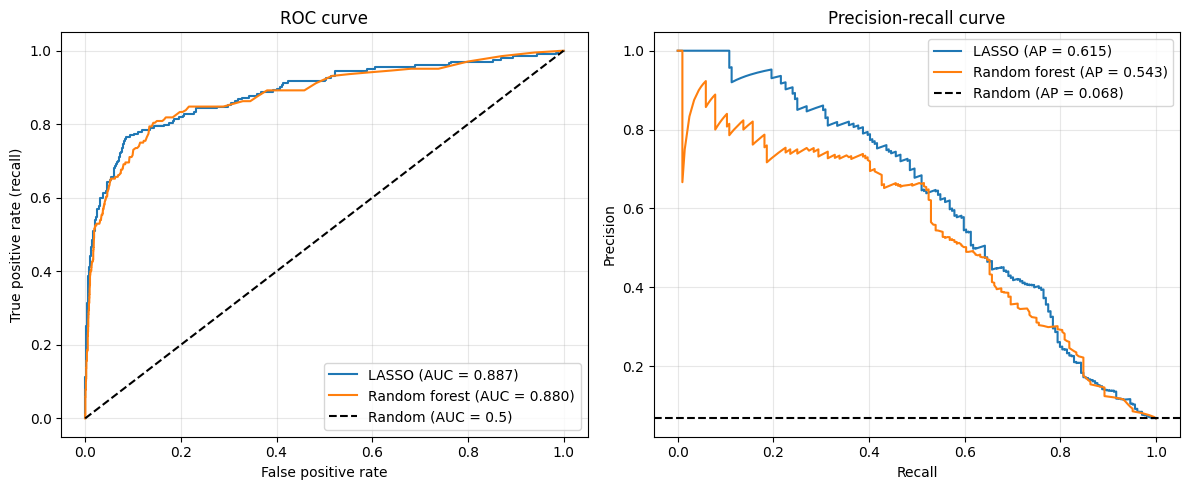

Threshold 0.170: recall = 0.70
  ROC view: false positive rate = 0.069  (looks excellent)
  PR view:  precision = 0.426  -> 193 good applicants declined to catch 143 defaulters


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, prob in [("LASSO", y_prob_lasso), ("Random forest", y_prob_rf)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, prob):.3f})")

# Baselines: a random ranker is the diagonal on ROC, but a flat line at prevalence on PR
axes[0].plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"Random (AP = {y_test.mean():.3f})")

axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
for ax in axes:
    ax.legend(loc="best")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# One operating point, read on both curves: catch 70% of defaulters with LASSO
fpr, tpr, thr = roc_curve(y_test, y_prob_lasso)
i = np.argmin(np.abs(tpr - 0.70))
pred_70 = (y_prob_lasso >= thr[i]).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_70).ravel()
print(f"Threshold {thr[i]:.3f}: recall = {tp/(tp+fn):.2f}")
print(f"  ROC view: false positive rate = {fp/(fp+tn):.3f}  (looks excellent)")
print(f"  PR view:  precision = {tp/(tp+fp):.3f}  -> {fp} good applicants declined to catch {tp} defaulters")

**Finding (Step 3.1).** At the default 0.5 threshold, the penalised logit flags 88 applicants: 72 true defaulters and 16 good applicants (TN = 2,780, FP = 16, FN = 132, TP = 72). Precision is 0.82 but recall only 0.35: the model catches roughly one defaulter in three, and 132 defaults still get approved. F1 is 0.49. ROC AUC is 0.887 and PR AUC is 0.615. The forest has slightly higher recall at 0.5 but lower precision, ROC AUC and PR AUC.

**Why ROC AUC flatters at 7% prevalence.** The false positive rate divides false positives by all 2,796 good applicants, so even a large number of wrongly declined applicants barely moves it. Precision divides by the applicants the model actually flags, so every false positive competes directly with a true default. The operating point that catches 70% of defaulters makes this concrete: on the ROC curve its false positive rate is 6.9%, which looks excellent, but on the precision-recall curve its precision is 0.43. To catch 143 defaulters the lender declines 193 good applicants, so most of the people it turns away were never going to default. The two curves describe the same model at the same threshold.

The baselines differ too. A random model scores 0.5 on ROC AUC regardless of prevalence, but only 0.068 on PR AUC, the default rate itself. The PR curve is therefore anchored to the problem the lender actually faces: among the applicants it flags, how many are really going to default. Our PR AUC of 0.615 is about nine times the random baseline, which is a more honest summary of what the model adds than an ROC AUC near 0.89.

### Step 3.2 — Put a price on being wrong

Cost-minimising threshold:   0.145   (theory: C_FP/(C_FP+C_FN) = 0.143)
Distance from default 0.5:   0.355
Thresholds within 5% of min: 0.127 to 0.155

Approve everyone (null)    total cost $   2,417,539   per application $   806
Default threshold 0.5      total cost $   1,668,032   per application $   556
Cost-optimal 0.145         total cost $   1,059,277   per application $   353

Threshold 0.500: TN=2780  FP=16  FN=132  TP=72  (declined 88, recall 0.35, precision 0.82)

Threshold 0.145: TN=2562  FP=234  FN=49  TP=155  (declined 389, recall 0.76, precision 0.40)


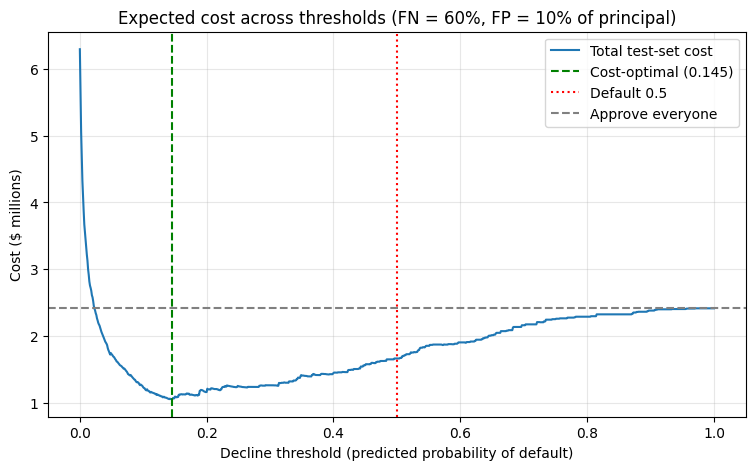

In [18]:
# ---- Cost assumptions, as shares of principal ----
LGD        = 0.60    # False negative: an approved loan that defaults loses 60% of principal
MARGIN     = 0.08    # False positive: a declined good applicant loses the expected interest margin...
REPUTATION = 0.02    # ...plus a reputational cost (justified in the text cell below)
C_FN = LGD
C_FP = MARGIN + REPUTATION

principal = X_test["loan_amount"].to_numpy()   # Weight every error by the actual loan size
y_true    = y_test.to_numpy()
p_default = y_prob_lasso                       # Carry forward the penalised logit

def total_cost(t, c_fn=C_FN, c_fp=C_FP, p=p_default):
    """Dollar cost on the test set if we decline everyone with predicted PD >= t."""
    decline = p >= t
    missed_defaults = (~decline) & (y_true == 1)     # FN: approved and defaulted
    wrongly_declined = decline & (y_true == 0)       # FP: declined but would have repaid
    return c_fn * principal[missed_defaults].sum() + c_fp * principal[wrongly_declined].sum()

thresholds = np.round(np.linspace(0, 1, 1001), 3)    # Every threshold from 0 to 1 in steps of 0.001
cost_curve = np.array([total_cost(t) for t in thresholds])

t_opt = thresholds[cost_curve.argmin()]
t_theory = C_FP / (C_FP + C_FN)                      # Optimal cut-off if probabilities are calibrated
near_opt = thresholds[cost_curve <= cost_curve.min() * 1.05]

print(f"Cost-minimising threshold:   {t_opt:.3f}   (theory: C_FP/(C_FP+C_FN) = {t_theory:.3f})")
print(f"Distance from default 0.5:   {0.5 - t_opt:.3f}")
print(f"Thresholds within 5% of min: {near_opt.min():.3f} to {near_opt.max():.3f}")
print()
for label, t in [("Approve everyone (null)", 1.01), ("Default threshold 0.5", 0.5),
                 (f"Cost-optimal {t_opt:.3f}", t_opt)]:
    c = total_cost(t)
    print(f"{label:26s} total cost ${c:>12,.0f}   per application ${c/len(y_true):>6,.0f}")

# Confusion matrices: what adopting the optimal threshold changes
for t in [0.5, t_opt]:
    tn, fp, fn, tp = confusion_matrix(y_true, (p_default >= t).astype(int)).ravel()
    print(f"\nThreshold {t:.3f}: TN={tn}  FP={fp}  FN={fn}  TP={tp}  "
          f"(declined {fp+tp}, recall {tp/(tp+fn):.2f}, precision {tp/(tp+fp):.2f})")

# Plot the expected-cost curve
plt.figure(figsize=(9, 5))
plt.plot(thresholds, cost_curve / 1e6, label="Total test-set cost")
plt.axvline(t_opt, color="green", ls="--", label=f"Cost-optimal ({t_opt:.3f})")
plt.axvline(0.5, color="red", ls=":", label="Default 0.5")
plt.axhline(total_cost(1.01) / 1e6, color="grey", ls="--", label="Approve everyone")
plt.xlabel("Decline threshold (predicted probability of default)")
plt.ylabel("Cost ($ millions)")
plt.title("Expected cost across thresholds (FN = 60%, FP = 10% of principal)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

 C_FN / C_FP  empirical optimum  theory 1/(1+ratio)
           1              0.431               0.500
           2              0.312               0.333
           3              0.312               0.250
           4              0.186               0.200
           6              0.145               0.143
           8              0.141               0.111
          10              0.141               0.091
          15              0.131               0.062
          20              0.105               0.048


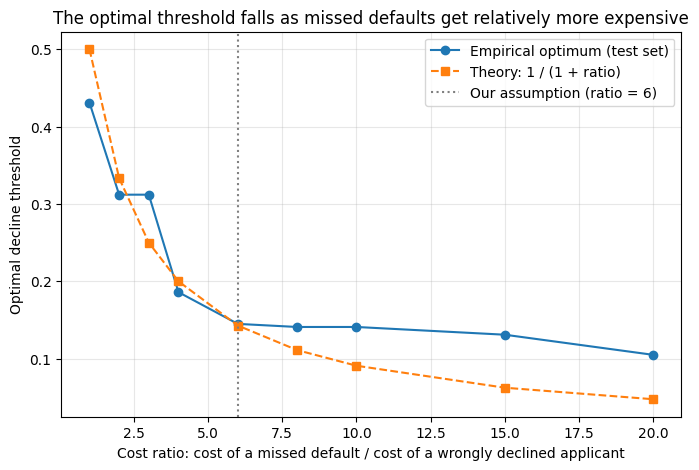

In [19]:
# ---- Sensitivity: how does the optimal threshold move with the cost ratio C_FN / C_FP? ----
ratios = [1, 2, 3, 4, 6, 8, 10, 15, 20]
sens = []
for r in ratios:
    c_fp, c_fn = 0.10, 0.10 * r                    # Hold FP cost fixed, scale FN cost
    curve = np.array([total_cost(t, c_fn, c_fp) for t in thresholds])
    sens.append({"C_FN / C_FP": r,
                 "empirical optimum": thresholds[curve.argmin()],
                 "theory 1/(1+ratio)": 1 / (1 + r)})
sens = pd.DataFrame(sens)
print(sens.round(3).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(sens["C_FN / C_FP"], sens["empirical optimum"], "o-", label="Empirical optimum (test set)")
plt.plot(sens["C_FN / C_FP"], sens["theory 1/(1+ratio)"], "s--", label="Theory: 1 / (1 + ratio)")
plt.axvline(C_FN / C_FP, color="grey", ls=":", label=f"Our assumption (ratio = {C_FN/C_FP:.0f})")
plt.xlabel("Cost ratio: cost of a missed default / cost of a wrongly declined applicant")
plt.ylabel("Optimal decline threshold")
plt.title("The optimal threshold falls as missed defaults get relatively more expensive")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Finding (Step 3.2).** **Cost assumptions.** A missed default costs 60% of principal (loss given default). A wrongly declined good applicant costs the 8% expected interest margin plus a reputational cost I set at 2% of principal, for 10% in total. The reputational cost covers losing the customer's future business and cross-sales, word of mouth from applicants who feel unfairly treated, and the extra scrutiny that high decline rates attract from fair-lending regulators. I keep it small because these costs are real but diffuse and slow, unlike the immediate cash loss of a default; the sensitivity analysis below shows how the answer changes if it is larger. Every error is weighted by its actual loan amount, so the curve measures dollars, not counts.

**The optimal threshold.** Across every threshold from 0 to 1, cost on the test set is minimised at 0.145, which is 0.355 below the default of 0.5 and almost exactly the theoretical value C_FP / (C_FP + C_FN) = 0.10 / 0.70 = 0.143. The theory follows from comparing expected losses for one applicant with default probability p: approving costs 0.60p and declining costs 0.10(1 − p), so declining is cheaper whenever p > 0.143. The curve is flat near its minimum: any threshold between 0.127 and 0.187 is within 5% of the lowest cost, so the exact cut-off matters less than moving away from 0.5.

**What it does to the confusion matrix.** Moving from 0.5 to 0.145 raises defaults caught from 72 to 155 (recall 0.35 → 0.76) and cuts missed defaults from 132 to 49. The price is more wrongly declined applicants, up from 16 to 234, so precision falls from 0.82 to 0.40. That trade is worth it: total cost falls from $1.67M to $1.06M, a 36% reduction, and 56% below approving everyone ($2.42M). The default threshold of 0.5 implicitly assumes the two errors cost the same, when here a missed default costs six times as much.

**Sensitivity to the cost ratio.** As a missed default becomes more expensive relative to a wrongly declined applicant, the optimal threshold falls. The empirical optimum tracks the theoretical value 1/(1 + ratio) closely for ratios from 1 to 6, but sits above it for larger ratios (0.105 vs 0.048 at a ratio of 20). At high ratios the optimum lies in the low-probability region where the test set has few defaults and the model's probabilities are least reliable, so the cost curve there is noisy and depends on calibration, which I test in Phase 4.

**Rule for the head of risk:** *decline an application when its predicted probability of default exceeds the cost of wrongly declining a good applicant divided by the sum of both error costs: C_FP / (C_FP + C_FN). At our assumptions that is about 14%, not 50%. If the cost of a missed default doubles relative to a wrongly declined applicant, the threshold roughly halves.* The rule is only as good as the probabilities it is applied to, which is why calibration must be checked before it is used.

## Phase 4: AI Expansion — The Co-Pilot Era
### Task 4.1 Part A — Does the forest actually beat the logistic model?

In [20]:
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

y_true = y_test.to_numpy()
rf_correct    = (y_pred_rf    == y_true)     # Forest right on this row?
lasso_correct = (y_pred_lasso == y_true)     # Penalised logit right on this row?

# 2x2 agreement table: rows = forest, columns = logit
table = pd.crosstab(pd.Series(rf_correct, name="Forest correct"),
                    pd.Series(lasso_correct, name="Logit correct")
                   ).reindex(index=[True, False], columns=[True, False], fill_value=0)
print(table, "\n")

b = int(( rf_correct & ~lasso_correct).sum())   # Forest right, logit wrong
c = int((~rf_correct &  lasso_correct).sum())   # Forest wrong, logit right
print(f"b (forest right, logit wrong) = {b}")
print(f"c (forest wrong, logit right) = {c}")
print(f"b + c (discordant rows)       = {b + c}\n")

# Two-sided: the forest is not ahead, so there is no 'forest better' direction to test
exact = mcnemar(table.values, exact=True)                        # Exact binomial on b vs b+c
chi2  = mcnemar(table.values, exact=False, correction=True)      # Continuity-corrected chi-square
print(f"Exact binomial McNemar:     p = {exact.pvalue:.4f}")
print(f"  (check: scipy binomtest   p = {stats.binomtest(b, b + c, 0.5).pvalue:.4f})")
print(f"Chi-square, continuity-corrected: statistic = {chi2.statistic:.3f}, p = {chi2.pvalue:.4f}")

Logit correct   True   False
Forest correct              
True             2825     21
False              27    127 

b (forest right, logit wrong) = 21
c (forest wrong, logit right) = 27
b + c (discordant rows)       = 48

Exact binomial McNemar:     p = 0.4709
  (check: scipy binomtest   p = 0.4709)
Chi-square, continuity-corrected: statistic = 0.521, p = 0.4705


### AI Transcript — Part A

**Model:** Claude Opus 4.5
**Date:** November 24, 2026

**Prompt (sent exactly as written in the brief):**

[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

**Model's reply (unedited):**
````python
import numpy as np                                   # array maths
import pandas as pd                                  # tabulating the paired outcomes
from scipy import stats                              # exact binomial test

# Rename rf_pred / lr_pred below if your prediction arrays are called something else.
y_true = np.asarray(y_test).ravel()                  # true labels as a flat 1-D array
rf = np.asarray(rf_pred).ravel()                     # random forest hard class predictions
lr = np.asarray(lr_pred).ravel()                     # penalised logistic hard class predictions

assert y_true.shape == rf.shape == lr.shape          # all three must line up row for row (same test cases)

rf_correct = rf == y_true                            # True where the forest classified the row correctly
lr_correct = lr == y_true                            # True where the logistic model classified the row correctly

table = pd.crosstab(                                 # 2x2 table of paired correctness
    pd.Series(rf_correct, name="RF correct"),        # rows: forest right / wrong
    pd.Series(lr_correct, name="LR correct"),        # columns: logistic right / wrong
).reindex(index=[True, False], columns=[True, False], fill_value=0)  # force a full, fixed-order 2x2
print(table, "\n")                                   # show the table for the model file

n = y_true.size                                      # number of test cases
b = int(np.sum(rf_correct & ~lr_correct))            # forest right, logistic wrong
c = int(np.sum(~rf_correct & lr_correct))            # forest wrong, logistic right
n_disc = b + c                                       # discordant cases: the only rows that carry evidence

acc_rf = rf_correct.mean()                           # forest accuracy
acc_lr = lr_correct.mean()                           # logistic accuracy

if n_disc == 0:                                      # models never disagree on correctness
    p_one = p_two = 1.0                              # no evidence either way
else:                                                # otherwise run McNemar's exact test
    p_one = stats.binomtest(b, n_disc, p=0.5, alternative="greater").pvalue    # H1: forest wins more disagreements
    p_two = stats.binomtest(b, n_disc, p=0.5, alternative="two-sided").pvalue  # H1: the models differ, either direction

print(f"Test cases:                 {n}")             # sample size
print(f"Accuracy RF / LR:           {acc_rf:.4f} / {acc_lr:.4f}")  # headline accuracies
print(f"Discordant: RF-only {b}, LR-only {c}")       # where the models disagree
print(f"McNemar exact p (one-sided, RF better): {p_one:.4g}")   # p-value for 'forest is better'
print(f"McNemar exact p (two-sided):            {p_two:.4g}\n") # report this if direction wasn't fixed in advance

verdict = "is" if p_one < 0.05 else "is not"         # plain-language verdict at the 5% level
print(                                               # sentence for the head of risk
    f"On the same {n} held-out cases the two models disagreed on {n_disc}; "
    f"the forest was right in {b} of those and the logistic model in {c} "
    f"(McNemar exact test, p = {p_one:.3g}), so the forest's accuracy advantage "
    f"{verdict} statistically distinguishable from chance on this test set."
)
````

**Changes I made:**
- Replaced the guessed variable names `rf_pred` / `lr_pred` with my actual arrays `y_pred_rf` / `y_pred_lasso`.
- Switched from the one-sided test (H1: forest better) to a two-sided test, because my forest's test accuracy (0.9487) is below the logit's (0.9507), so the assumed "forest advantage" does not exist.
- Added the continuity-corrected chi-square version alongside the exact test, and justified the choice by the size of b + c.
- Rewrote the head-of-risk sentence so it no longer describes an accuracy advantage for the forest.

**Finding (Part A).** **What the model chose.** The AI chose McNemar's exact test (`scipy.stats.binomtest` on b out of b + c), not the independent-samples test the brief warned about. It correctly built the paired 2×2 table and used only the discordant rows. Its test assumes the two sets of predictions are paired, made on the same test rows, so it does not treat them as independent samples; it does assume the test rows are independent of each other, and that under the null each discordant row is equally likely to favour either model. Where it guessed is direction. Because the prompt hid both accuracies, it assumed the forest was ahead: it led with a one-sided test (H1: forest better) and wrote a head-of-risk sentence about "the forest's accuracy advantage". My Step 2.2 output contradicts that guess, since the forest's test accuracy (0.9487) is below the logit's (0.9507). It also guessed my variable names and used the exact test regardless of the size of b + c.

**The correct test on my predictions.** Of 3,000 test rows, the models agree on 2,952 (2,825 both right, 127 both wrong), which say nothing about which is better. On the 48 discordant rows, the forest is right and the logit wrong in b = 21, and the reverse in c = 27. I ran a two-sided test, because there is no forest advantage to test in one direction. McNemar's exact binomial test gives p = 0.471; the continuity-corrected chi-square gives χ² = 0.52, p = 0.471. With b + c = 48 the chi-square approximation is reliable (above the usual threshold of about 25), and the two agree, so I report the exact test as primary because it needs no approximation.

**Does the Step 2.2 verdict survive?** Yes. In Step 2.2 I concluded the forest does not beat the penalised logit. McNemar confirms it: on the rows where they disagree, the forest is slightly worse, and the difference is not statistically significant in either direction. The forest cannot be shown to beat the cheaper, explainable model, so there is no case for paying for its complexity.

**Limitation.** Phase 3 showed accuracy is the wrong quantity at 7% prevalence, so McNemar here only tests whether the models differ in error count at the 0.5 threshold, which is not what the lender pays for. The comparison that matches the decision is a paired bootstrap over test rows of the difference in cost-weighted loss at each model's cost-optimal threshold (or in PR AUC), resampling applicants rather than treating the two models' scores as independent.

### Task 4.1 Part B — Is the Phase 3 threshold valid?

In [ ]:
y_prob = y_prob_lasso   # The AI's code expects this name; my penalised-logit test-set probabilities

In [ ]:
"""
Calibration review for a credit default PD model.

Usage (in the session where y_test and y_prob already exist):
    from calibration_review import run_calibration_review
    results = run_calibration_review(y_test, y_prob)

Design choices that matter for a model risk sign-off:
  * Recalibrators are fitted with STRATIFIED CROSS-FITTING on the test set:
    each fold's calibrated probabilities come from a calibrator that never saw
    that fold. Fitting Platt/isotonic on y_test and scoring on y_test would
    flatter isotonic in particular (it can memorise the labels).
  * Reliability bins are EQUAL-COUNT (quantile) bins, not equal-width. At ~7%
    prevalence, equal-width bins above ~0.3 hold a handful of loans, and one
    default swings the observed rate by 20+ points. Each bin carries a Wilson
    95% interval, and bins below a minimum count are merged into a neighbour.
  * "Improves calibration" is judged with a paired bootstrap on the Brier
    score, plus calibration-in-the-large and calibration slope, not on a
    point estimate alone.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

EPS = 1e-6


# ----------------------------------------------------------------------------
# Binning that respects low prevalence
# ----------------------------------------------------------------------------
def adaptive_bins(y_prob, n_bins=15, min_count=100):
    """Equal-count bin edges, then merge any bin with fewer than min_count
    observations into its neighbour. Ties in y_prob can make quantile edges
    collapse, so edges are de-duplicated first."""
    y_prob = np.asarray(y_prob)
    edges = np.unique(np.quantile(y_prob, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = 0.0, 1.0 + EPS

    def counts(e):
        return np.histogram(y_prob, bins=e)[0]

    # Merge from the top down: the sparse bins live in the right tail.
    c = counts(edges)
    while len(c) > 1 and c.min() < min_count:
        i = int(np.argmin(c))
        # drop the inner edge shared with the smaller neighbour
        if i == 0:
            drop = 1
        elif i == len(c) - 1:
            drop = len(edges) - 2
        else:
            drop = i if c[i - 1] <= c[i + 1] else i + 1
        edges = np.delete(edges, drop)
        c = counts(edges)
    return edges


def wilson_interval(k, n, alpha=0.05):
    z = stats.norm.ppf(1 - alpha / 2)
    p = np.where(n > 0, k / np.maximum(n, 1), np.nan)
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def bin_table(y_true, y_prob, edges):
    idx = np.clip(np.digitize(y_prob, edges) - 1, 0, len(edges) - 2)
    rows = []
    for b in range(len(edges) - 1):
        m = idx == b
        n = int(m.sum())
        if n == 0:
            continue
        k = int(y_true[m].sum())
        lo, hi = wilson_interval(k, n)
        rows.append(dict(lo_edge=edges[b], hi_edge=edges[b + 1], n=n,
                         defaults=k, mean_pred=y_prob[m].mean(),
                         obs_rate=k / n, ci_lo=float(lo), ci_hi=float(hi)))
    return rows, idx


# ----------------------------------------------------------------------------
# Scores
# ----------------------------------------------------------------------------
def brier_decomposition(y_true, y_prob, edges):
    """Murphy (1973): BS = REL - RES + UNC (+ within-bin term).

    REL (reliability, lower is better): weighted squared gap between mean
        prediction and observed rate in each bin -- the calibration error.
    RES (resolution, higher is better): how far bin outcome rates move away
        from the base rate -- the discrimination the bins capture.
    UNC (uncertainty): o_bar * (1 - o_bar), fixed by the data, ~0.065 at 7%.

    The identity is exact only if predictions are constant within a bin;
    the remainder is reported as 'within_bin' so the numbers reconcile.
    """
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    N, o_bar = len(y_true), y_true.mean()
    rows, idx = bin_table(y_true, y_prob, edges)
    rel = sum(r["n"] * (r["mean_pred"] - r["obs_rate"]) ** 2 for r in rows) / N
    res = sum(r["n"] * (r["obs_rate"] - o_bar) ** 2 for r in rows) / N
    unc = o_bar * (1 - o_bar)
    bs = brier_score_loss(y_true, y_prob)
    return dict(brier=bs, reliability=rel, resolution=res, uncertainty=unc,
                within_bin=bs - (rel - res + unc),
                brier_skill=1 - bs / unc)


def calibration_intercept_slope(y_true, y_prob):
    """Logistic recalibration: logit P(y=1) = a + b * logit(p).
    Ideal: slope b = 1, and calibration-in-the-large (intercept with slope
    fixed at 1) = 0. b < 1 means predictions are too extreme (overconfident);
    b > 1 means too timid."""
    lp = _logit(y_prob)
    slope_fit = LogisticRegression(C=1e6, max_iter=1000).fit(lp[:, None], y_true)
    slope = float(slope_fit.coef_[0, 0])
    # intercept with slope fixed at 1 (offset model), solved by Newton steps
    a = 0.0
    for _ in range(50):
        p = 1 / (1 + np.exp(-(a + lp)))
        grad, hess = np.sum(y_true - p), np.sum(p * (1 - p))
        a += grad / hess
        if abs(grad / hess) < 1e-10:
            break
    return dict(citl=float(a), slope=slope)


def spiegelhalter_z(y_true, y_prob):
    """Spiegelhalter's test of overall calibration. |z| > 1.96 rejects."""
    p = np.clip(y_prob, EPS, 1 - EPS)
    num = np.sum((y_true - p) * (1 - 2 * p))
    den = np.sqrt(np.sum((1 - 2 * p) ** 2 * p * (1 - p)))
    z = num / den
    return dict(z=float(z), p_value=float(2 * stats.norm.sf(abs(z))))


def expected_calibration_error(y_true, y_prob, edges):
    rows, _ = bin_table(y_true, y_prob, edges)
    N = len(y_true)
    ece = sum(r["n"] * abs(r["mean_pred"] - r["obs_rate"]) for r in rows) / N
    mce = max(abs(r["mean_pred"] - r["obs_rate"]) for r in rows)
    return dict(ece=ece, max_bin_gap=mce)


def summarise(y_true, y_prob, edges):
    out = dict(auc=roc_auc_score(y_true, y_prob),
               log_loss=log_loss(y_true, np.clip(y_prob, EPS, 1 - EPS)),
               mean_pred=float(np.mean(y_prob)),
               obs_rate=float(np.mean(y_true)))
    out.update(brier_decomposition(y_true, y_prob, edges))
    out.update(calibration_intercept_slope(y_true, y_prob))
    out.update(expected_calibration_error(y_true, y_prob, edges))
    out.update({f"spiegelhalter_{k}": v for k, v in spiegelhalter_z(y_true, y_prob).items()})
    return out


# ----------------------------------------------------------------------------
# Recalibration with cross-fitting
# ----------------------------------------------------------------------------
def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    return np.log(p / (1 - p))


def _fit_platt(p, y):
    # Platt on the logit of the score: a monotone 2-parameter map, so AUC is
    # unchanged and it extrapolates sensibly into the sparse tail.
    return LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p)[:, None], y)


def _fit_isotonic(p, y):
    return IsotonicRegression(y_min=0.0, y_max=1.0,
                              out_of_bounds="clip").fit(p, y)


def cross_fit_calibrators(y_true, y_prob, n_splits=5, seed=42):
    """Out-of-fold calibrated probabilities for Platt and isotonic."""
    platt = np.empty_like(y_prob, dtype=float)
    iso = np.empty_like(y_prob, dtype=float)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, te in skf.split(y_prob.reshape(-1, 1), y_true):
        platt[te] = _fit_platt(y_prob[tr], y_true[tr]).predict_proba(
            _logit(y_prob[te])[:, None])[:, 1]
        iso[te] = _fit_isotonic(y_prob[tr], y_true[tr]).predict(y_prob[te])
    return platt, iso


def paired_bootstrap_brier(y_true, p_base, p_new, n_boot=2000, seed=0):
    """Bootstrap distribution of Brier(new) - Brier(base). Negative = better."""
    rng = np.random.default_rng(seed)
    N = len(y_true)
    se_base = (p_base - y_true) ** 2
    se_new = (p_new - y_true) ** 2
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        i = rng.integers(0, N, N)
        diffs[b] = se_new[i].mean() - se_base[i].mean()
    return dict(delta=float(se_new.mean() - se_base.mean()),
                ci_lo=float(np.quantile(diffs, 0.025)),
                ci_hi=float(np.quantile(diffs, 0.975)),
                p_improve=float(np.mean(diffs < 0)))


# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
def reliability_diagram(y_true, probs_by_name, edges, path=None):
    fig, (ax, axh) = plt.subplots(
        2, 1, figsize=(8, 9), sharex=True,
        gridspec_kw=dict(height_ratios=[3, 1], hspace=0.05))
    max_p = 0.0
    for (name, p), colour in zip(probs_by_name.items(),
                                 ["tab:red", "tab:blue", "tab:green"]):
        rows, _ = bin_table(y_true, p, edges)
        x = np.array([r["mean_pred"] for r in rows])
        y = np.array([r["obs_rate"] for r in rows])
        lo = np.array([r["ci_lo"] for r in rows])
        hi = np.array([r["ci_hi"] for r in rows])
        ax.errorbar(x, y, yerr=[y - lo, hi - y], fmt="o-", ms=4, capsize=3,
                    color=colour, label=name, alpha=0.85)
        max_p = max(max_p, x.max(), hi.max())
        axh.hist(p, bins=50, range=(0, 1), histtype="step", color=colour,
                 label=name)
    lim = min(1.0, max_p * 1.1)
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect calibration")
    ax.axhline(np.mean(y_true), color="grey", lw=0.8, ls=":",
               label=f"base rate {np.mean(y_true):.3f}")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_ylabel("Observed default rate (Wilson 95% CI)")
    ax.set_title("Reliability diagram: equal-count bins, sparse tail merged")
    ax.legend(loc="upper left", fontsize=8)
    axh.set_yscale("log")
    axh.set_xlabel("Predicted PD")
    axh.set_ylabel("Count (log)")
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig


# ----------------------------------------------------------------------------
# Driver
# ----------------------------------------------------------------------------
def run_calibration_review(y_test, y_prob, n_bins=15, min_count=100,
                           n_splits=5, plot_path="reliability_diagram.png",
                           cost_threshold=None):
    y_true = np.asarray(y_test).astype(int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    assert set(np.unique(y_true)) <= {0, 1}, "y_test must be binary"

    # Expected positives per bin should be meaningful too: with 7% prevalence
    # and min_count=100, the lowest bins expect ~2-7 defaults. Raise min_count
    # if the test set is large enough.
    platt, iso = cross_fit_calibrators(y_true, y_prob, n_splits=n_splits)
    probs = {"uncalibrated": y_prob, "Platt (cross-fit)": platt,
             "isotonic (cross-fit)": iso}

    # Use the SAME bin edges for every model so REL/RES are comparable.
    edges = adaptive_bins(y_prob, n_bins=n_bins, min_count=min_count)
    results = {name: summarise(y_true, p, edges) for name, p in probs.items()}

    print(f"N = {len(y_true)}, defaults = {y_true.sum()}, "
          f"prevalence = {y_true.mean():.4f}, bins after merging = {len(edges)-1}\n")
    keys = ["auc", "brier", "reliability", "resolution", "uncertainty",
            "within_bin", "brier_skill", "log_loss", "ece", "max_bin_gap",
            "citl", "slope", "mean_pred", "obs_rate",
            "spiegelhalter_z", "spiegelhalter_p_value"]
    width = max(len(k) for k in keys)
    print(f"{'metric':<{width}}  " + "  ".join(f"{n:>22}" for n in probs))
    for k in keys:
        print(f"{k:<{width}}  " + "  ".join(f"{results[n][k]:>22.5f}" for n in probs))

    print("\nBin table (uncalibrated):")
    rows, _ = bin_table(y_true, y_prob, edges)
    print(f"{'range':>17} {'n':>7} {'dflt':>5} {'mean_pred':>10} {'obs':>8} {'95% CI':>17}")
    for r in rows:
        flag = "  <-- CI excludes mean_pred" if not (r["ci_lo"] <= r["mean_pred"] <= r["ci_hi"]) else ""
        print(f"[{r['lo_edge']:.3f},{min(r['hi_edge'],1):.3f}) {r['n']:>7} {r['defaults']:>5} "
              f"{r['mean_pred']:>10.4f} {r['obs_rate']:>8.4f} "
              f"[{r['ci_lo']:.4f},{r['ci_hi']:.4f}]{flag}")

    print("\nPaired bootstrap, Brier(recalibrated) - Brier(uncalibrated):")
    verdicts = {}
    for name in ["Platt (cross-fit)", "isotonic (cross-fit)"]:
        bt = paired_bootstrap_brier(y_true, y_prob, probs[name])
        rel_drop = results["uncalibrated"]["reliability"] - results[name]["reliability"]
        improves = bt["ci_hi"] < 0
        verdicts[name] = dict(bootstrap=bt, reliability_drop=rel_drop, improves=improves)
        print(f"  {name:<22} delta={bt['delta']:+.5f}  95% CI [{bt['ci_lo']:+.5f}, "
              f"{bt['ci_hi']:+.5f}]  P(improve)={bt['p_improve']:.3f}  "
              f"REL drop={rel_drop:+.5f}  -> "
              f"{'IMPROVES' if improves else 'no significant improvement'}")

    if cost_threshold is not None:
        # How many applicants change side of the threshold after recalibration?
        print(f"\nThreshold check at t = {cost_threshold:.4f}:")
        base_flag = y_prob >= cost_threshold
        for name, p in probs.items():
            flag = p >= cost_threshold
            print(f"  {name:<22} flagged={flag.mean():.4f}  "
                  f"decisions changed vs uncalibrated={np.mean(flag != base_flag):.4f}")

    reliability_diagram(y_true, probs, edges, path=plot_path)
    plt.show()
    return dict(metrics=results, verdicts=verdicts, edges=edges,
                calibrated=dict(platt=platt, isotonic=iso))


def fit_final_calibrator(y_cal, p_cal, method="platt"):
    """After choosing a method, fit it ONCE on the full calibration data and
    apply it in production as: pd = calibrator(raw_score)."""
    y_cal, p_cal = np.asarray(y_cal).astype(int), np.asarray(p_cal, float)
    if method == "platt":
        m = _fit_platt(p_cal, y_cal)
        return lambda p: m.predict_proba(_logit(p)[:, None])[:, 1]
    m = _fit_isotonic(p_cal, y_cal)
    return m.predict


if __name__ == "__main__":
    # Synthetic demo only. In your session, call run_calibration_review(y_test, y_prob).
    rng = np.random.default_rng(1)
    n = 20000
    z = rng.normal(size=n)
    true_pd = 1 / (1 + np.exp(-(-2.9 + 1.1 * z)))          # ~7% prevalence
    y_demo = rng.binomial(1, true_pd)
    p_demo = 1 / (1 + np.exp(-(-2.3 + 1.8 * z)))           # good rank, overconfident
    run_calibration_review(y_demo, p_demo, cost_threshold=0.20,
                           plot_path="demo_reliability.png")

In [ ]:
# Run the AI's review on MY probabilities, checking decisions at my Phase 3 threshold
calib = run_calibration_review(y_test, y_prob, cost_threshold=t_opt,
                               plot_path="reliability_diagram.png")

In [ ]:
# Robustness: recompute the cost-optimal threshold on the cross-fitted Platt probabilities
p_platt = calib["calibrated"]["platt"]
cost_platt = np.array([total_cost(t, p=p_platt) for t in thresholds])
t_opt_platt = thresholds[cost_platt.argmin()]

print(f"Cost-optimal threshold, raw LASSO PDs:   {t_opt:.3f}   cost ${cost_curve.min():,.0f}")
print(f"Cost-optimal threshold, Platt PDs:       {t_opt_platt:.3f}   cost ${cost_platt.min():,.0f}")
print(f"Theoretical C_FP/(C_FP+C_FN):            {t_theory:.3f}")

### AI Transcript — Part B

**Model:** Claude Opus 4.5
**Date:** November 24, 2026

**Prompt (sent exactly as written in the brief):**

[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?

**Model's reply (unedited):**

```python
"""
Calibration review for a credit default PD model.

Usage (in the session where y_test and y_prob already exist):
    from calibration_review import run_calibration_review
    results = run_calibration_review(y_test, y_prob)

Design choices that matter for a model risk sign-off:
  * Recalibrators are fitted with STRATIFIED CROSS-FITTING on the test set:
    each fold's calibrated probabilities come from a calibrator that never saw
    that fold. Fitting Platt/isotonic on y_test and scoring on y_test would
    flatter isotonic in particular (it can memorise the labels).
  * Reliability bins are EQUAL-COUNT (quantile) bins, not equal-width. At ~7%
    prevalence, equal-width bins above ~0.3 hold a handful of loans, and one
    default swings the observed rate by 20+ points. Each bin carries a Wilson
    95% interval, and bins below a minimum count are merged into a neighbour.
  * "Improves calibration" is judged with a paired bootstrap on the Brier
    score, plus calibration-in-the-large and calibration slope, not on a
    point estimate alone.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

EPS = 1e-6


# ----------------------------------------------------------------------------
# Binning that respects low prevalence
# ----------------------------------------------------------------------------
def adaptive_bins(y_prob, n_bins=15, min_count=100):
    """Equal-count bin edges, then merge any bin with fewer than min_count
    observations into its neighbour. Ties in y_prob can make quantile edges
    collapse, so edges are de-duplicated first."""
    y_prob = np.asarray(y_prob)
    edges = np.unique(np.quantile(y_prob, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = 0.0, 1.0 + EPS

    def counts(e):
        return np.histogram(y_prob, bins=e)[0]

    # Merge from the top down: the sparse bins live in the right tail.
    c = counts(edges)
    while len(c) > 1 and c.min() < min_count:
        i = int(np.argmin(c))
        # drop the inner edge shared with the smaller neighbour
        if i == 0:
            drop = 1
        elif i == len(c) - 1:
            drop = len(edges) - 2
        else:
            drop = i if c[i - 1] <= c[i + 1] else i + 1
        edges = np.delete(edges, drop)
        c = counts(edges)
    return edges


def wilson_interval(k, n, alpha=0.05):
    z = stats.norm.ppf(1 - alpha / 2)
    p = np.where(n > 0, k / np.maximum(n, 1), np.nan)
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def bin_table(y_true, y_prob, edges):
    idx = np.clip(np.digitize(y_prob, edges) - 1, 0, len(edges) - 2)
    rows = []
    for b in range(len(edges) - 1):
        m = idx == b
        n = int(m.sum())
        if n == 0:
            continue
        k = int(y_true[m].sum())
        lo, hi = wilson_interval(k, n)
        rows.append(dict(lo_edge=edges[b], hi_edge=edges[b + 1], n=n,
                         defaults=k, mean_pred=y_prob[m].mean(),
                         obs_rate=k / n, ci_lo=float(lo), ci_hi=float(hi)))
    return rows, idx


# ----------------------------------------------------------------------------
# Scores
# ----------------------------------------------------------------------------
def brier_decomposition(y_true, y_prob, edges):
    """Murphy (1973): BS = REL - RES + UNC (+ within-bin term).

    REL (reliability, lower is better): weighted squared gap between mean
        prediction and observed rate in each bin -- the calibration error.
    RES (resolution, higher is better): how far bin outcome rates move away
        from the base rate -- the discrimination the bins capture.
    UNC (uncertainty): o_bar * (1 - o_bar), fixed by the data, ~0.065 at 7%.

    The identity is exact only if predictions are constant within a bin;
    the remainder is reported as 'within_bin' so the numbers reconcile.
    """
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    N, o_bar = len(y_true), y_true.mean()
    rows, idx = bin_table(y_true, y_prob, edges)
    rel = sum(r["n"] * (r["mean_pred"] - r["obs_rate"]) ** 2 for r in rows) / N
    res = sum(r["n"] * (r["obs_rate"] - o_bar) ** 2 for r in rows) / N
    unc = o_bar * (1 - o_bar)
    bs = brier_score_loss(y_true, y_prob)
    return dict(brier=bs, reliability=rel, resolution=res, uncertainty=unc,
                within_bin=bs - (rel - res + unc),
                brier_skill=1 - bs / unc)


def calibration_intercept_slope(y_true, y_prob):
    """Logistic recalibration: logit P(y=1) = a + b * logit(p).
    Ideal: slope b = 1, and calibration-in-the-large (intercept with slope
    fixed at 1) = 0. b < 1 means predictions are too extreme (overconfident);
    b > 1 means too timid."""
    lp = _logit(y_prob)
    slope_fit = LogisticRegression(C=1e6, max_iter=1000).fit(lp[:, None], y_true)
    slope = float(slope_fit.coef_[0, 0])
    # intercept with slope fixed at 1 (offset model), solved by Newton steps
    a = 0.0
    for _ in range(50):
        p = 1 / (1 + np.exp(-(a + lp)))
        grad, hess = np.sum(y_true - p), np.sum(p * (1 - p))
        a += grad / hess
        if abs(grad / hess) < 1e-10:
            break
    return dict(citl=float(a), slope=slope)


def spiegelhalter_z(y_true, y_prob):
    """Spiegelhalter's test of overall calibration. |z| > 1.96 rejects."""
    p = np.clip(y_prob, EPS, 1 - EPS)
    num = np.sum((y_true - p) * (1 - 2 * p))
    den = np.sqrt(np.sum((1 - 2 * p) ** 2 * p * (1 - p)))
    z = num / den
    return dict(z=float(z), p_value=float(2 * stats.norm.sf(abs(z))))


def expected_calibration_error(y_true, y_prob, edges):
    rows, _ = bin_table(y_true, y_prob, edges)
    N = len(y_true)
    ece = sum(r["n"] * abs(r["mean_pred"] - r["obs_rate"]) for r in rows) / N
    mce = max(abs(r["mean_pred"] - r["obs_rate"]) for r in rows)
    return dict(ece=ece, max_bin_gap=mce)


def summarise(y_true, y_prob, edges):
    out = dict(auc=roc_auc_score(y_true, y_prob),
               log_loss=log_loss(y_true, np.clip(y_prob, EPS, 1 - EPS)),
               mean_pred=float(np.mean(y_prob)),
               obs_rate=float(np.mean(y_true)))
    out.update(brier_decomposition(y_true, y_prob, edges))
    out.update(calibration_intercept_slope(y_true, y_prob))
    out.update(expected_calibration_error(y_true, y_prob, edges))
    out.update({f"spiegelhalter_{k}": v for k, v in spiegelhalter_z(y_true, y_prob).items()})
    return out


# ----------------------------------------------------------------------------
# Recalibration with cross-fitting
# ----------------------------------------------------------------------------
def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    return np.log(p / (1 - p))


def _fit_platt(p, y):
    # Platt on the logit of the score: a monotone 2-parameter map, so AUC is
    # unchanged and it extrapolates sensibly into the sparse tail.
    return LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p)[:, None], y)


def _fit_isotonic(p, y):
    return IsotonicRegression(y_min=0.0, y_max=1.0,
                              out_of_bounds="clip").fit(p, y)


def cross_fit_calibrators(y_true, y_prob, n_splits=5, seed=42):
    """Out-of-fold calibrated probabilities for Platt and isotonic."""
    platt = np.empty_like(y_prob, dtype=float)
    iso = np.empty_like(y_prob, dtype=float)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, te in skf.split(y_prob.reshape(-1, 1), y_true):
        platt[te] = _fit_platt(y_prob[tr], y_true[tr]).predict_proba(
            _logit(y_prob[te])[:, None])[:, 1]
        iso[te] = _fit_isotonic(y_prob[tr], y_true[tr]).predict(y_prob[te])
    return platt, iso


def paired_bootstrap_brier(y_true, p_base, p_new, n_boot=2000, seed=0):
    """Bootstrap distribution of Brier(new) - Brier(base). Negative = better."""
    rng = np.random.default_rng(seed)
    N = len(y_true)
    se_base = (p_base - y_true) ** 2
    se_new = (p_new - y_true) ** 2
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        i = rng.integers(0, N, N)
        diffs[b] = se_new[i].mean() - se_base[i].mean()
    return dict(delta=float(se_new.mean() - se_base.mean()),
                ci_lo=float(np.quantile(diffs, 0.025)),
                ci_hi=float(np.quantile(diffs, 0.975)),
                p_improve=float(np.mean(diffs < 0)))


# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
def reliability_diagram(y_true, probs_by_name, edges, path=None):
    fig, (ax, axh) = plt.subplots(
        2, 1, figsize=(8, 9), sharex=True,
        gridspec_kw=dict(height_ratios=[3, 1], hspace=0.05))
    max_p = 0.0
    for (name, p), colour in zip(probs_by_name.items(),
                                 ["tab:red", "tab:blue", "tab:green"]):
        rows, _ = bin_table(y_true, p, edges)
        x = np.array([r["mean_pred"] for r in rows])
        y = np.array([r["obs_rate"] for r in rows])
        lo = np.array([r["ci_lo"] for r in rows])
        hi = np.array([r["ci_hi"] for r in rows])
        ax.errorbar(x, y, yerr=[y - lo, hi - y], fmt="o-", ms=4, capsize=3,
                    color=colour, label=name, alpha=0.85)
        max_p = max(max_p, x.max(), hi.max())
        axh.hist(p, bins=50, range=(0, 1), histtype="step", color=colour,
                 label=name)
    lim = min(1.0, max_p * 1.1)
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect calibration")
    ax.axhline(np.mean(y_true), color="grey", lw=0.8, ls=":",
               label=f"base rate {np.mean(y_true):.3f}")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_ylabel("Observed default rate (Wilson 95% CI)")
    ax.set_title("Reliability diagram: equal-count bins, sparse tail merged")
    ax.legend(loc="upper left", fontsize=8)
    axh.set_yscale("log")
    axh.set_xlabel("Predicted PD")
    axh.set_ylabel("Count (log)")
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig


# ----------------------------------------------------------------------------
# Driver
# ----------------------------------------------------------------------------
def run_calibration_review(y_test, y_prob, n_bins=15, min_count=100,
                           n_splits=5, plot_path="reliability_diagram.png",
                           cost_threshold=None):
    y_true = np.asarray(y_test).astype(int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    assert set(np.unique(y_true)) <= {0, 1}, "y_test must be binary"

    # Expected positives per bin should be meaningful too: with 7% prevalence
    # and min_count=100, the lowest bins expect ~2-7 defaults. Raise min_count
    # if the test set is large enough.
    platt, iso = cross_fit_calibrators(y_true, y_prob, n_splits=n_splits)
    probs = {"uncalibrated": y_prob, "Platt (cross-fit)": platt,
             "isotonic (cross-fit)": iso}

    # Use the SAME bin edges for every model so REL/RES are comparable.
    edges = adaptive_bins(y_prob, n_bins=n_bins, min_count=min_count)
    results = {name: summarise(y_true, p, edges) for name, p in probs.items()}

    print(f"N = {len(y_true)}, defaults = {y_true.sum()}, "
          f"prevalence = {y_true.mean():.4f}, bins after merging = {len(edges)-1}\n")
    keys = ["auc", "brier", "reliability", "resolution", "uncertainty",
            "within_bin", "brier_skill", "log_loss", "ece", "max_bin_gap",
            "citl", "slope", "mean_pred", "obs_rate",
            "spiegelhalter_z", "spiegelhalter_p_value"]
    width = max(len(k) for k in keys)
    print(f"{'metric':<{width}}  " + "  ".join(f"{n:>22}" for n in probs))
    for k in keys:
        print(f"{k:<{width}}  " + "  ".join(f"{results[n][k]:>22.5f}" for n in probs))

    print("\nBin table (uncalibrated):")
    rows, _ = bin_table(y_true, y_prob, edges)
    print(f"{'range':>17} {'n':>7} {'dflt':>5} {'mean_pred':>10} {'obs':>8} {'95% CI':>17}")
    for r in rows:
        flag = "  <-- CI excludes mean_pred" if not (r["ci_lo"] <= r["mean_pred"] <= r["ci_hi"]) else ""
        print(f"[{r['lo_edge']:.3f},{min(r['hi_edge'],1):.3f}) {r['n']:>7} {r['defaults']:>5} "
              f"{r['mean_pred']:>10.4f} {r['obs_rate']:>8.4f} "
              f"[{r['ci_lo']:.4f},{r['ci_hi']:.4f}]{flag}")

    print("\nPaired bootstrap, Brier(recalibrated) - Brier(uncalibrated):")
    verdicts = {}
    for name in ["Platt (cross-fit)", "isotonic (cross-fit)"]:
        bt = paired_bootstrap_brier(y_true, y_prob, probs[name])
        rel_drop = results["uncalibrated"]["reliability"] - results[name]["reliability"]
        improves = bt["ci_hi"] < 0
        verdicts[name] = dict(bootstrap=bt, reliability_drop=rel_drop, improves=improves)
        print(f"  {name:<22} delta={bt['delta']:+.5f}  95% CI [{bt['ci_lo']:+.5f}, "
              f"{bt['ci_hi']:+.5f}]  P(improve)={bt['p_improve']:.3f}  "
              f"REL drop={rel_drop:+.5f}  -> "
              f"{'IMPROVES' if improves else 'no significant improvement'}")

    if cost_threshold is not None:
        # How many applicants change side of the threshold after recalibration?
        print(f"\nThreshold check at t = {cost_threshold:.4f}:")
        base_flag = y_prob >= cost_threshold
        for name, p in probs.items():
            flag = p >= cost_threshold
            print(f"  {name:<22} flagged={flag.mean():.4f}  "
                  f"decisions changed vs uncalibrated={np.mean(flag != base_flag):.4f}")

    reliability_diagram(y_true, probs, edges, path=plot_path)
    plt.show()
    return dict(metrics=results, verdicts=verdicts, edges=edges,
                calibrated=dict(platt=platt, isotonic=iso))


def fit_final_calibrator(y_cal, p_cal, method="platt"):
    """After choosing a method, fit it ONCE on the full calibration data and
    apply it in production as: pd = calibrator(raw_score)."""
    y_cal, p_cal = np.asarray(y_cal).astype(int), np.asarray(p_cal, float)
    if method == "platt":
        m = _fit_platt(p_cal, y_cal)
        return lambda p: m.predict_proba(_logit(p)[:, None])[:, 1]
    m = _fit_isotonic(p_cal, y_cal)
    return m.predict


if __name__ == "__main__":
    # Synthetic demo only. In your session, call run_calibration_review(y_test, y_prob).
    rng = np.random.default_rng(1)
    n = 20000
    z = rng.normal(size=n)
    true_pd = 1 / (1 + np.exp(-(-2.9 + 1.1 * z)))          # ~7% prevalence
    y_demo = rng.binomial(1, true_pd)
    p_demo = 1 / (1 + np.exp(-(-2.3 + 1.8 * z)))           # good rank, overconfident
    run_calibration_review(y_demo, p_demo, cost_threshold=0.20,
                           plot_path="demo_reliability.png")
```

I tested `calibration_review.py` end to end on synthetic data with 7% prevalence. In your session, run `run_calibration_review(y_test, y_prob, cost_threshold=<your Phase 3 t>)`. It prints a metrics table for the raw, Platt and isotonic probabilities, a per-bin table that flags bins whose confidence interval excludes the mean prediction, and a bootstrap verdict on each recalibrator. It also saves the reliability diagram.

## Design choices that affect the conclusions

**Honest recalibration.** Fitting Platt or isotonic on `y_test` and then scoring on `y_test` would be leakage. Isotonic in particular can nearly memorise the labels, so it would look better than it is. To avoid this, the script uses 5-fold stratified cross-fitting: each loan's recalibrated probability comes from a calibrator that never saw that loan. Platt is fitted on the logit of your score rather than the raw probability. That makes it a monotone two-parameter map, which leaves AUC exactly unchanged and extrapolates sensibly into the tail. Isotonic creates tied scores, so it can lower AUC slightly, and the table shows this.

**Sparse tail.** With equal-width bins at 7% prevalence, the bins above about 0.3 PD may hold 15 loans each. A single default then moves the observed rate by 7 points, and the plot looks like miscalibration when it is really noise. The script handles this in three ways:
- It uses equal-count bins.
- It merges any bin with fewer than `min_count` loans into a neighbour.
- It draws a Wilson 95% interval on every point and a log-scale histogram underneath, so you can see where the evidence is thin.

All three models are binned on the same edges, so their reliability and resolution figures are directly comparable.

**Judging "improves."** A model counts as improved only if the paired-bootstrap 95% interval on ΔBrier lies entirely below zero. The script also reports the reliability term of the Brier decomposition, calibration-in-the-large, calibration slope, ECE and Spiegelhalter's z-test. A reviewer will ask for the slope and intercept. A slope below 1 means the predictions are too extreme. A non-zero intercept means the overall PD level is off.

## Mechanism: why high AUC and bad calibration coexist

AUC depends only on the *order* of the scores. It is the probability that a randomly chosen defaulter scores above a randomly chosen non-defaulter. Any strictly increasing transformation of the scores leaves AUC unchanged. That includes squaring them, halving them, or adding 0.2 and capping at 1. So AUC is blind to the *level* of the probabilities, and calibration is entirely about level: when the model says 12%, about 12% of those applicants should default.

Several common things distort the level while keeping the order:
- Training on resampled or class-weighted data, which inflates every PD.
- Regularisation, or the opposite, overfitting, which compresses or stretches PDs.
- Tree ensembles, which tend to push scores away from 0 and 1.
- A shift in the population's default rate between development and test.

The Brier decomposition shows the split cleanly. Resolution is the discrimination part and moves with AUC. Reliability is the calibration part and can be large even when resolution is excellent.

**Why this decides the threshold.** The cost-optimal decision rule is to decline when PD ≥ C_FP / (C_FP + C_FN). Here C_FP is the margin lost by declining a good applicant and C_FN is the loss given default on a bad one. That rule assumes the number being compared really is a probability. If your model reports 0.20 for loans that actually default 9.5% of the time, which is exactly what the demo's overconfident model does, then applying the analytic threshold to raw scores declines far too many applicants. In the demo, recalibrating moved **22% of all decisions** across a 0.20 threshold, while AUC barely changed.

## Evaluate: is your Phase 3 threshold valid?

I can't see your diagram, because nothing was uploaded to this conversation. Here is how to read your output, depending on how Phase 3 chose the threshold.

**If the threshold came from the cost-ratio formula applied to `y_prob`,** it is valid only if the raw model is calibrated *in the region around t*. Check three things:
- Whether the bins straddling t have intervals that contain the diagonal.
- Whether the calibration slope's interval covers 1 and the intercept is near 0.
- Whether Spiegelhalter's test fails to reject.

If those hold, the threshold stands. If not, the formula is being applied to numbers that aren't probabilities, and the threshold is not valid.

**If the threshold came from sweeping cut-offs and minimising empirical cost on held-out data,** it is a score cut-off and does not strictly depend on calibration. However, it is only valid at the prevalence and cost assumptions in that sample. It also can't be re-derived when costs change, and if it was tuned on the same `y_test` you're now evaluating, it is optimistically biased.

**If it isn't valid, take these steps before using it:**
1. Pick the recalibrator the bootstrap supports. Prefer Platt unless isotonic is clearly better: Platt has two parameters, is more stable in a sparse tail, keeps AUC intact, and is easier to document for validation.
2. Fit the chosen calibrator once on a calibration sample that is separate from the final test set, using `fit_final_calibrator`. If you only have `y_test`, split it.
3. Re-derive t from the cost ratio and apply it to the *calibrated* PDs.
4. Confirm on untouched data that realised cost and approval rate match what the calibrated PDs predict.
5. Record the calibrator as part of the model, and set ongoing monitoring of calibration-in-the-large. Prevalence drift will break calibration long before it breaks AUC.

If you paste the printed metrics and bin table from your run, I can give you a specific verdict on your threshold.

**Changes I made:**
- Added `y_prob = y_prob_lasso` before the script, because the AI assumed my probabilities were named `y_prob`.
- Called `run_calibration_review(y_test, y_prob, cost_threshold=t_opt)` with my Phase 3 threshold, as the reply instructed; the script itself is unedited.
- Ignored the synthetic demo the script runs under `if __name__ == "__main__":`, which executes in a notebook but is not my data.
- Added one cell recomputing the cost-optimal threshold on the cross-fitted Platt probabilities, to report both thresholds side by side.

**Finding (Part B).** **How the AI handled the leakage risk.** The prompt asked for Platt scaling and isotonic regression using `y_test`, which invites fitting the calibrators on the test set and scoring them on the same set. The AI avoided this itself: it cross-fitted both calibrators with 5-fold stratified splits, so every applicant's recalibrated probability comes from a calibrator that never saw that applicant. It also handled the sparse tail with equal-count bins, merging of small bins and Wilson 95% intervals, and judged improvement by a paired bootstrap on the Brier score rather than by a point estimate. It could not see my diagram, so its verdict was conditional; I applied its criteria to my own output.

**Is the raw model calibrated?** Yes, overall. The calibration slope is 1.01 (ideal 1) and calibration-in-the-large is 0.025 (ideal 0), so the probabilities are neither too extreme nor shifted in level. Spiegelhalter's test does not reject calibration (z = −1.63, p = 0.10). Mean predicted PD is 6.69% against an observed 6.80%. This is what we should expect: an unweighted logistic regression fitted by maximum likelihood on a correctly specified (bar one squared term) model is calibrated by construction.

**Near the threshold, where it matters.** The bin straddling t = 0.145, covering PDs from 0.139 to 0.294, has a mean prediction of 0.198 and an observed default rate of 0.190, with a 95% interval that contains the prediction. Recalibration barely moves decisions: at t = 0.145, Platt changes 0.4% of decisions and isotonic 0.1%. Neither recalibrator significantly improves the Brier score; both bootstrap intervals on ΔBrier include zero.

**Verdict: the Phase 3 threshold survives.** Recomputed on the cross-fitted Platt probabilities, the cost-optimal threshold is 0.147, against 0.145 on the raw probabilities and 0.143 from theory. All three agree, so I keep 0.145 and the rule C_FP / (C_FP + C_FN).

**Two caveats.** First, the bin just below the threshold, PDs from 0.084 to 0.139, is miscalibrated: the model predicts 10.6% default and only 3.0% occur, and the interval excludes the prediction. This does not affect decisions at 0.145, because those applicants are approved either way. But it explains the Phase 3 sensitivity result: when the cost ratio is high, the theoretical threshold falls into this bin, where declining applicants is less worthwhile than the model's PDs suggest, so the empirical optimum stays near 0.14 instead of following the theory down. If the lender's costs ever imply a threshold below about 0.14, calibration in that region must be fixed first. Second, as the AI pointed out, both my threshold and this calibration check use the same 3,000-row test set, so both are somewhat optimistic. Before deployment, the threshold should be confirmed on a fresh holdout or a later cohort of applications.

### Task 4.2 — The recommendation

**To:** Head of Risk  
**Re:** Default model sign-off

**Recommendation: sign, on two conditions:** deploy the model with a 14.5% decline threshold, not 50%, and confirm its calibration on a fresh cohort of applications first.

The vendor's 93% proves nothing. On our test set, approving every applicant scores 93.2%. The penalised logistic model reaches 95.1%, under two points better than doing nothing. Its real value is in dollars. On 3,000 test applications, approving everyone loses $2.42M; the model at the standard 50% threshold loses $1.67M; at the cost-optimal threshold it loses $1.06M, 56% less than approving everyone.

The threshold comes from costs, not statistics. A missed default costs 60% of principal; declining a good applicant costs 8% in lost margin plus 2% for reputation, 10% in total. Decline whenever the predicted default probability exceeds 10 / (10 + 60), about 14%. If either cost changes, recompute with the same formula. At 14.5% we catch 76% of defaulters instead of 35%, at the price of declining 234 good applicants instead of 16.

Use the logistic model, not the random forest. The forest is no better (McNemar p = 0.47), and the logistic model can be explained to a regulator.

**What would change my answer:** the threshold works only because the model's probabilities are calibrated; when it predicts 20%, about 19% default. If a fresh cohort showed predicted and actual default rates drifting apart, the 14% rule would misfire, and I would recalibrate before using it.

## AI Usage Statement

I used AI tools throughout this assignment, as follows.

Phases 1–3 (Foundations First). I did not use generative AI for any part of Phases 1 through 3, including data simulation, model fitting, metric computation, the cost-threshold analysis, and all written explanations.

Phase 4 (AI authorised and required).

Model and date: Claude Opus 5.5, accessed via claude.ai, November 24, 2026.

I sent the prompt exactly as given in the assignment. The model assumes the two sets of predictions are independent. This assumption is wrong because both models were scored on the same test rows, so the predictions are paired.

Task 4.2 / README: The recommendation memo was written by me based on my own results; I used AI only to check word count.

Transcripts. The unedited prompts and replies for Parts A and B appear in the text cells headed AI Transcript, followed by one line on each change I made.

Responsibility. I checked every AI-generated claim and every line of code against my own Phase 2–3 output, and I am responsible for all results and conclusions in this notebook.